# 01 — Sources de données et test de faisabilité (GO / NO-GO)

**Objectif.** Avant d'écrire un pipeline lourd, nous voulons savoir si le projet tient **sur de vraies données** : y
a-t-il assez de capteurs citoyens près de stations officielles, sur une période où la vérité terrain est vérifiée, avec
des fichiers que nous savons lire, et dans un volume que notre disque peut accueillir ?

**Ce qu'on va voir.**

1. à quoi ressemble un fichier brut de capteur citoyen ;
2. combien de capteurs étaient actifs en 2024–2025 ;
3. sur quelle horloge sont les capteurs, et avec quelle précision ils sont positionnés ;
4. comment nous obtenons la position de 23 000 capteurs sans tout télécharger ;
5. les stations officielles et leurs données vérifiées ;
6. sur quelle horloge sont les stations (un contrôle décisif) ;
7. combien de paires capteur ↔ station nous pouvons former ;
8. le volume disque attendu ;
9. la recommandation GO / NO-GO.

**Comment le lire.** Chaque section part d'une question, montre le calcul (une cellule de code courte qui appelle
`src/aircalib/`), puis dit ce que nous observons, ce que ça veut dire et ce que nous décidons. Les encadrés
**🔎 Contrôle** signalent les vérifications qui protègent la suite du projet d'une erreur.

**Vocabulaire de ce notebook.**

- **PM2.5 / PM10** : masse des particules de diamètre inférieur à 2,5 / 10 micromètres, en microgrammes par mètre cube
  d'air (µg/m³).
- **Capteur citoyen** : boîtier à bas coût installé par un particulier ; le plus courant est le **SDS011**, un compteur
  optique à environ 30 € du réseau Sensor.Community.
- **Sonde météo** : petit capteur d'humidité et de température (BME280, DHT22…), souvent branché sur le même boîtier.
- **Site** (`location`) : l'emplacement physique d'un boîtier ; la sonde de particules et la sonde météo ont des
  identifiants différents mais le même site.
- **Station de référence** : station réglementaire dont les mesures sont **vérifiées** par l'organisme national ; c'est
  notre « vérité terrain ».
- **Paire** : un capteur citoyen associé à une station de référence proche.

## 0. Préparation

Nous chargeons la configuration centrale (`configs/default.yaml`) et les modules du projet. Aucune valeur (dates,
rayons, adresses) n'est écrite en dur dans le notebook. Les résultats réseau sont mis en cache dans `data/meta/` : une
nouvelle exécution relit ce cache au lieu de retélécharger.

In [1]:
from datetime import date

import matplotlib.pyplot as plt
import polars as pl

from aircalib.config import get_settings
from aircalib.ingest import discovery, eea
from aircalib.logging import setup_logging

setup_logging("WARNING")
settings = get_settings()
TODAY = date(2026, 10, 13)  # date of the discovery run (cache key of the live snapshot)
FIG_DIR = settings.paths.reports_dir / "figures"
FIG_DIR.mkdir(parents=True, exist_ok=True)
pl.Config(tbl_rows=30, tbl_cols=14, fmt_str_lengths=45, tbl_width_chars=160)
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False})
print("période étudiée :", settings.period.start, "→", settings.period.end)

période étudiée : 2024-01-01 → 2025-12-31


## 1. À quoi ressemble un fichier brut de capteur citoyen ?

**Question.** Nous voulons connaître le format réel des fichiers avant d'écrire le moindre programme de lecture : la
règle du projet est de ne jamais supposer un format.

**Ce que nous regardons.** Trois jours réels (15–17 mars 2024) de trois capteurs : un capteur de particules SDS011 et
deux sondes météo (BME280 et DHT22).

In [2]:
examples = [
    {"sensor_type": "sds011", "sensor_id": 7334},
    {"sensor_type": "bme280", "sensor_id": 18678},
    {"sensor_type": "dht22", "sensor_id": 7530},
]
raw = {}
for e in examples:
    raw[e["sensor_type"]] = await discovery.sensor_days(settings, e, date(2024, 3, 15), 3, TODAY)
for sensor_type, frame in raw.items():
    print(f"{sensor_type}: {frame.height} lignes, colonnes = {frame.columns}")
raw["sds011"].head(4)

sds011: 1684 lignes, colonnes = ['sensor_id', 'sensor_type', 'location', 'lat', 'lon', 'timestamp', 'P1', 'durP1', 'ratioP1', 'P2', 'durP2', 'ratioP2']
bme280: 843 lignes, colonnes = ['sensor_id', 'sensor_type', 'location', 'lat', 'lon', 'timestamp', 'pressure', 'altitude', 'pressure_sealevel', 'temperature', 'humidity']
dht22: 1746 lignes, colonnes = ['sensor_id', 'sensor_type', 'location', 'lat', 'lon', 'timestamp', 'temperature', 'humidity']


sensor_id,sensor_type,location,lat,lon,timestamp,P1,durP1,ratioP1,P2,durP2,ratioP2
str,str,str,str,str,str,str,str,str,str,str,str
"""7334""","""SDS011""","""3708""","""42.632""","""23.378""","""2024-03-15T00:02:11""","""12.55""",null,null,"""7.03""",null,null
"""7334""","""SDS011""","""3708""","""42.632""","""23.378""","""2024-03-15T00:04:43""","""9.95""",null,null,"""6.50""",null,null
"""7334""","""SDS011""","""3708""","""42.632""","""23.378""","""2024-03-15T00:07:09""","""12.30""",null,null,"""7.05""",null,null
"""7334""","""SDS011""","""3708""","""42.632""","""23.378""","""2024-03-15T00:09:35""","""11.02""",null,null,"""6.38""",null,null


**Ce que nous observons.** Les trois fichiers ont un en-tête et des colonnes séparées par des points-virgules. Les six
premières colonnes (`sensor_id`, `sensor_type`, `location`, `lat`, `lon`, `timestamp`) sont communes à tous les types ;
viennent ensuite les mesures propres au type : `P1` (PM10) et `P2` (PM2.5) pour le SDS011, `pressure`, `temperature`,
`humidity` pour le BME280, `temperature` et `humidity` pour le DHT22. Le capteur 7334 est en Bulgarie (42,6° N ;
23,4° E).

**Ce que ça veut dire.** L'archive est **mondiale** : il faudra filtrer par position. Nous lisons tout **en texte** à
l'ingestion, sans rien transformer, et nous ne typerons les valeurs qu'au nettoyage : une conversion ratée ne doit pas
faire disparaître une ligne en silence.

**Question.** Combien de mesures un capteur envoie-t-il par heure, et l'humidité des sondes est-elle crédible ?

**Ce que nous regardons.** Sur ces trois fichiers : l'écart médian entre deux mesures (la **cadence**), les colonnes
toujours vides, et la part des mesures d'humidité « collées » au plafond (≥ 99,9 %).

In [3]:
def profile(frame: pl.DataFrame) -> dict:
    ts = frame["timestamp"].str.to_datetime("%Y-%m-%dT%H:%M:%S").sort()
    empty = [c for c in frame.columns if frame[c].null_count() == frame.height]
    out = {
        "lignes": frame.height,
        "cadence_médiane_s": ts.diff().dt.total_seconds().median(),
        "colonnes_vides": empty,
    }
    if "humidity" in frame.columns:
        rh = frame["humidity"].cast(pl.Float64)
        out |= {
            "humidité_min": rh.min(),
            "humidité_max": rh.max(),
            "part_humidité_≥99.9": round((rh >= 99.9).mean(), 3),
        }
    if "P2" in frame.columns:
        p2 = frame["P2"].cast(pl.Float64)
        out |= {"PM2.5_min": p2.min(), "PM2.5_médiane": p2.median(), "PM2.5_max": p2.max()}
    return out


pl.DataFrame([{"capteur": k, **{k2: str(v2) for k2, v2 in profile(v).items()}} for k, v in raw.items()])

capteur,lignes,cadence_médiane_s,colonnes_vides,PM2.5_min,PM2.5_médiane,PM2.5_max,humidité_min,humidité_max,part_humidité_≥99.9
str,str,str,str,str,str,str,str,str,str
"""sds011""","""1684""","""146.0""","""['durP1', 'ratioP1', 'durP2', 'ratioP2']""","""1.38""","""6.88""","""15.88""",null,null,null
"""bme280""","""843""","""306.0""","""['altitude', 'pressure_sealevel']""",null,null,null,"""54.23""","""100.0""","""0.553"""
"""dht22""","""1746""","""146.0""","""[]""",null,null,null,"""19.2""","""99.9""","""0.497"""


**Ce que nous observons.**

- **Cadence** : 146 s entre deux mesures pour le SDS011 et le DHT22, 306 s pour ce BME280, soit environ 25 et 12
  mesures par heure.
- **Colonnes toujours vides** : `durP1`, `ratioP1`, `durP2`, `ratioP2` (héritées d'un ancien capteur, le PPD42NS) et,
  pour le BME280, `altitude` et `pressure_sealevel`.
- **Humidité** : sur ces trois jours de mars, **55 %** des mesures du BME280 et **50 %** de celles du DHT22 valent
  99,9 % ou plus.
- Les PM2.5 de ce SDS011 restent dans une plage plausible (1,4 à 15,9 µg/m³).

**Ce que ça veut dire.** Le nombre de mesures attendues par heure dépend du capteur : notre règle de complétude
horaire (étape 3) utilisera la cadence propre à chaque capteur, pas un nombre fixe. Une humidité de 100 % existe
(brouillard), mais la moitié du temps en mars, c'est plutôt le signe d'une sonde saturée. La variable la plus
importante de la correction est donc aussi la plus sale.

**Décision.** L'humidité aura sa règle de qualité dédiée (notebook 02) ; les colonnes toujours vides sont ignorées.

## 2. Combien de capteurs étaient actifs en 2024–2025 ?

**Question.** L'interface « live » de Sensor.Community ne montre que les capteurs actifs **aujourd'hui** : un capteur
tombé en panne en 2025 y est invisible. Nous voulons la liste des capteurs actifs **sur la période**.

**Ce que nous regardons.** L'archive publie un dossier par jour, avec un fichier par capteur. Nous lisons la **liste
des fichiers** (pas leur contenu) d'un jour par mois, le 15, soit 24 listes pour 2024–2025.

**Pourquoi un jour par mois.** Lister les 731 jours prendrait environ 13 h (chaque liste fait environ 5 Mo et met
environ 65 s à arriver). Un jour par mois suffit à savoir quels mois chaque capteur a fonctionné. Limite : un capteur
actif seulement entre deux 15 du mois est manqué ; l'activité exacte sera recalculée au téléchargement (notebook 02).

In [4]:
listings = await discovery.collect_listings(settings, TODAY)
print(f"{listings.height:,} fichiers capteur-jour sur {listings['date'].n_unique()} jours échantillonnés")
by_type = (
    listings.group_by("sensor_type")
    .agg(
        fichiers=pl.len(),
        capteurs=pl.col("sensor_id").n_unique(),
        part_indoor=pl.col("indoor").mean().round(3),
    )
    .sort("capteurs", descending=True)
)
by_type.head(12)

515,616 fichiers capteur-jour sur 24 jours échantillonnés


sensor_type,fichiers,capteurs,part_indoor
str,u32,u32,f64
"""sds011""",256554,16451,0.027
"""bme280""",114482,7817,0.041
"""dht22""",96231,5990,0.031
"""sps30""",8702,686,0.028
"""laerm""",6194,524,0.02
"""bmp280""",5870,473,0.056
"""pms5003""",5263,398,0.113
"""pms7003""",4917,362,0.066
"""sht31""",5823,360,0.022


**Ce que nous observons.** Les 24 listes contiennent **515 616 fichiers** capteur-jour. Le SDS011 domine (16 451
capteurs distincts dans le monde), devant les sondes d'humidité BME280 (7 817) et DHT22 (5 990). Les capteurs de
particules PMS5003, PMS7003 et SPS30 comptent moins de 700 capteurs chacun. Les capteurs déclarés *indoor* (suffixe
`_indoor` dans le nom du fichier) font 2,7 % des fichiers SDS011.

**Ce que ça veut dire.** Le SDS011 est le seul capteur assez répandu pour apprendre un modèle. Un capteur d'intérieur ne
mesure pas l'air extérieur : nous l'excluons.

**Question.** Le réseau est-il stable sur la période, ou y a-t-il des ruptures (panne de l'archive, changement de
format) ?

**Ce que nous regardons.** Le nombre de capteurs actifs le 15 de chaque mois, par type.

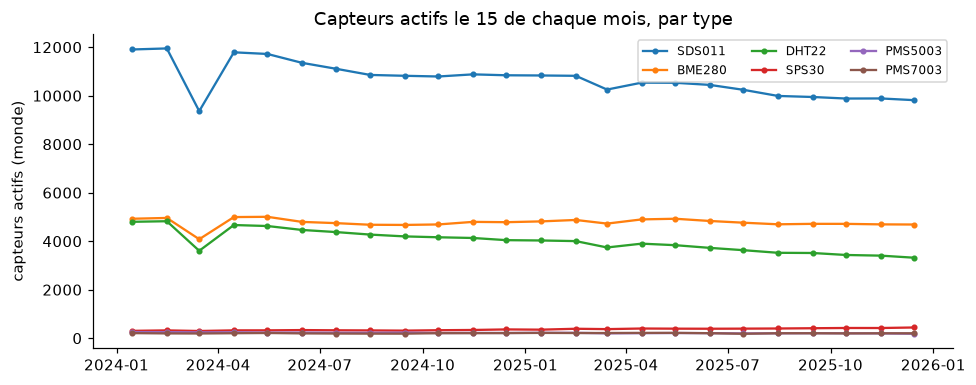

In [5]:
cfg = settings.sensor_community
monthly = (
    listings.filter(pl.col("sensor_type").is_in(cfg.pm_types + cfg.humidity_types))
    .group_by("date", "sensor_type")
    .len()
    .sort("date")
)
fig, ax = plt.subplots(figsize=(9, 3.6))
for sensor_type in ["sds011", "bme280", "dht22", "sps30", "pms5003", "pms7003"]:
    part = monthly.filter(pl.col("sensor_type") == sensor_type)
    ax.plot(part["date"], part["len"], marker="o", ms=3, label=sensor_type.upper())
ax.set_ylabel("capteurs actifs (monde)")
ax.set_title("Capteurs actifs le 15 de chaque mois, par type")
ax.legend(ncols=3, fontsize=8)
fig.tight_layout()
fig.savefig(FIG_DIR / "01_capteurs_actifs_par_mois.png")

**Ce que nous observons.** Entre **9 363 et 11 948 SDS011** sont actifs le 15 de chaque mois dans le monde, entre
4 082 et 5 006 BME280, entre 3 319 et 4 824 DHT22. Aucune chute brutale n'apparaît.

**Ce que ça veut dire.** La période 2024–2025 est utilisable telle quelle, sans trou d'archive à contourner.

## 3. Sur quelle horloge sont les capteurs, et sont-ils bien positionnés ?

**Question.** Pour aligner un capteur et une station heure par heure, nous devons connaître le fuseau horaire des
capteurs. Nous voulons aussi savoir si leurs positions sont précises.

**Ce que nous regardons.** L'instantané de l'interface live (tous les capteurs ayant émis dans les 5 dernières
minutes) : nous comparons l'horodatage le plus récent à l'heure UTC à laquelle nous avons fait la requête. Le drapeau
`exact_location` indique si les coordonnées sont précises ou arrondies.

In [6]:
live = await discovery.live_snapshot(settings, TODAY)
if "retrieved_at_utc" in live.columns:
    lag = (live["retrieved_at_utc"][0] - live["timestamp"].max()).total_seconds()
    print(f"requête à {live['retrieved_at_utc'][0]} UTC")
    print(f"mesure la plus récente {live['timestamp'].max()} → écart {lag:.0f} s")
print(f"part des capteurs à position exacte : {live['exact_location'].mean():.1%}")
(
    live.filter(
        pl.col("sensor_type").is_in(["sds011", "bme280", "dht22", "sps30"]),
        pl.col("country").is_in(["DE", "FR", "NL", "BE"]),
    )
    .group_by("country", "sensor_type")
    .agg(capteurs=pl.len(), part_indoor=pl.col("indoor").mean().round(3))
    .pivot(on="sensor_type", index="country", values="capteurs")
    .sort("country")
)

requête à 2026-10-13 15:42:20.864558 UTC
mesure la plus récente 2026-10-13 15:41:18 → écart 63 s
part des capteurs à position exacte : 34.4%


country,dht22,sds011,sps30,bme280
str,u32,u32,u32,u32
"""BE""",260,373,16,83
"""DE""",1382,3614,123,1418
"""FR""",80,250,5,125
"""NL""",424,1203,229,571


**Ce que nous observons.**

- La mesure la plus récente date de **63 s** avant l'heure UTC de la requête.
- Seuls **34 %** des capteurs ont une position exacte ; les autres sont arrondis à 3 décimales, soit environ 110 m.
- L'Allemagne compte environ 3 600 SDS011 actifs aujourd'hui, la France environ 250.

**Ce que ça veut dire.** Les horodatages de Sensor.Community sont en **UTC** (temps universel, sans heure d'été). Une
imprécision de 110 m est sans conséquence pour des paires à 0,5 km ou plus, mais elle limite l'analyse de l'erreur
selon la distance à cette résolution.

**Décision.** L'Allemagne, avec environ quatorze fois plus de SDS011 actifs, sert à l'apprentissage ; la France sert
de test de transfert.

## 4. Où est chaque capteur ? Une requête de 2 Ko par capteur

**Question.** Nous avons besoin de la position de chaque capteur vu dans l'archive, mais télécharger un fichier
complet par capteur serait long et chargerait inutilement des serveurs associatifs.

**Ce que nous regardons.** Pour chaque capteur de particules ou d'humidité, nous ne téléchargeons que les **2 premiers
kilo-octets** de son fichier le plus récent (requête HTTP *Range*), nous décompressons ce début et lisons la première
ligne : identifiant de site, latitude, longitude. Nous sautons les capteurs que l'instantané live place aujourd'hui
hors d'Allemagne et de France (un capteur aujourd'hui éteint est, lui, toujours lu).

In [7]:
candidates = discovery.head_candidates(
    listings, live, cfg.pm_types + cfg.humidity_types, settings.discovery.countries
)
positions = await discovery.resolve_positions(settings, candidates, TODAY)
inventory = discovery.sensor_inventory(listings, positions, settings)
seen = listings.filter(pl.col("sensor_type").is_in(cfg.pm_types + cfg.humidity_types))["sensor_id"].n_unique()
print(f"capteurs PM/humidité vus dans l'archive : {seen:,}")
print(f"  sautés (à l'étranger aujourd'hui) : {seen - candidates.height:,}")
print(f"  lus par requête Range : {candidates.height:,}")
n_ok, n_fail = positions["lat"].is_not_null().sum(), positions["lat"].is_null().sum()
print(f"  positions obtenues : {n_ok:,} ; échecs : {n_fail:,}")
inventory.group_by("kind").agg(
    capteurs=pl.len(),
    part_indoor=pl.col("indoor").mean().round(3),
    mois_actifs_médian=pl.col("n_months").median(),
)

capteurs PM/humidité vus dans l'archive : 32,285
  sautés (à l'étranger aujourd'hui) : 8,909
  lus par requête Range : 23,376
  positions obtenues : 23,477 ; échecs : 0


kind,capteurs,part_indoor,mois_actifs_médian
str,u32,f64,f64
"""humidity""",10571,0.049,15.0
"""pm""",12906,0.045,15.0


**Ce que nous observons.** Sur 32 285 capteurs de particules ou d'humidité vus dans l'archive, **8 909 sont sautés**
(aujourd'hui hors d'Allemagne et de France) et 23 376 sont lus en environ 6 minutes, **sans aucun échec** (environ 65
requêtes par seconde). L'inventaire compte 12 906 capteurs de particules et 10 571 sondes d'humidité, actifs en
médiane 15 mois sur 24. **54 capteurs déclarent la position (0 ; 0)**, dans le golfe de Guinée.

**Ce que ça veut dire.** La lecture partielle divise par trois le volume téléchargé pour la même information. Les
capteurs en (0 ; 0) sont mal configurés : ils ne seront appariés à aucune station, ce qui est le comportement voulu.

## 5. Les stations officielles : quelles données, et sont-elles vérifiées ?

**Question.** Nous voulons les stations qui mesurent le PM2.5 **à l'heure**, avec des données **vérifiées**, en
Allemagne et en France.

**Ce que nous regardons.** Les métadonnées de toutes les stations européennes de l'Agence européenne de
l'environnement (EEA). Nous gardons les points de mesure PM2.5 automatiques (une valeur par heure) qui ont un fichier
**E1a**. E1a désigne les données **vérifiées** par chaque pays, par opposition à E2a, le flux temps réel non vérifié.
Une station peut abriter plusieurs instruments : on parle de **points de prélèvement** (*sampling points*).

In [8]:
stations = await discovery.eea_stations(settings, "pm25")
print(f"{stations.height} points PM2.5 horaires E1a, {stations['station_code'].n_unique()} stations")
stations.group_by("country", "station_type").agg(
    points=pl.len(), stations=pl.col("station_code").n_unique()
).sort("country", "station_type")

682 points PM2.5 horaires E1a, 682 stations


country,station_type,points,stations
str,str,u32,u32
"""DE""","""background""",240,240
"""DE""","""industrial""",21,21
"""DE""","""traffic""",121,121
"""FR""","""background""",214,214
"""FR""","""industrial""",13,13
"""FR""","""traffic""",73,73


Nous regardons ensuite quels instruments mesurent le PM2.5, pays par pays.

In [9]:
stations.group_by("country", "measurement_method").len().sort("country", "len", descending=[False, True])

country,measurement_method,len
str,str,u32
"""DE""","""light-scat""",283
"""DE""","""nephelometry+beta""",62
"""DE""","""TEOM""",21
"""DE""","""BETA""",16
"""FR""","""OPC-CMC""",145
"""FR""","""TEOM-FDMS""",81
"""FR""","""BETA""",61
"""FR""","""""",13


**Ce que nous observons.** **682 points de prélèvement PM2.5 horaires vérifiés** (382 en Allemagne, 300 en France
métropolitaine), un seul par station. Les stations de **fond** (éloignées des sources directes) sont majoritaires,
mais un tiers des stations allemandes sont des stations **trafic** (en bord de route). Les instruments diffèrent : en
Allemagne surtout la diffusion de lumière (`light-scat`), en France surtout un compteur optique (`OPC-CMC`) et une
microbalance (`TEOM-FDMS`). Nous écartons les 25 stations françaises d'outre-mer (autre fuseau, aucun capteur proche)
et 19 points européens sans coordonnées.

**Ce que ça veut dire.** La vérité terrain n'est pas parfaitement homogène entre les deux pays : c'est une limite à
garder en tête pour le test de transfert vers la France.

**Question.** Quelles heures d'une station pouvons-nous garder ?

**Ce que nous regardons.** La structure d'un fichier E1a réel (la première station allemande téléchargée) : colonnes,
types, drapeaux. Selon le vocabulaire officiel de l'EEA, `Validity` vaut −1 (non valide), −99 (maintenance), 1
(valide), 2 ou 3 (valide, sous la limite de détection) ; `Verification` vaut 1 (vérifié), 2 (préliminaire) ou 3 (non
vérifié).

In [10]:
from aircalib.ingest.http import polite_client

downloaded = pl.read_parquet(settings.paths.meta / "eea_pm25_monthly_valid_hours.parquet")[
    "sampling_point"
].unique()
example = (
    stations.filter(pl.col("country") == "DE", pl.col("sampling_point").is_in(downloaded.implode()))
    .sort("sampling_point")
    .row(0, named=True)
)
one_path = discovery.eea_raw_path(settings, "pm25", "DE", example["sampling_point"])
if not one_path.exists():  # raw files are deleted once bronze holds them (eea.keep_raw): fetch this one again
    async with polite_client(settings.http) as client:
        await eea.download_parquet(client, example["url"], one_path)
one = pl.read_parquet(one_path)
print(
    example["station_name"],
    "·",
    example["station_type"],
    example["station_area"],
    "·",
    one_path.name,
    one.shape,
)
print(one.schema)
obs_one = eea.scan_observations(one_path).collect()
(
    obs_one.group_by(year=pl.col("start").dt.year())
    .agg(
        heures=pl.len(),
        valides=pl.col("validity").is_in(settings.eea.valid_codes).sum(),
        sentinelle_m999=(pl.col("value") == settings.eea.missing_sentinel).sum(),
        vérifiées=(pl.col("verification") == 1).sum(),
        min=pl.col("value").filter(pl.col("validity") > 0).min(),
        max=pl.col("value").max(),
    )
    .sort("year")
    .tail(4)
)

Potsdam-Zentrum · background urban · SPO.DE_DEBB021_PM2_dataGroup1.parquet (113952, 12)
Schema({'Samplingpoint': String, 'Pollutant': Int32, 'Start': Datetime(time_unit='ns', time_zone=None), 'End': Datetime(time_unit='ns', time_zone=None), 'Value': Decimal(precision=38, scale=18), 'Unit': String, 'AggType': String, 'Validity': Int32, 'Verification': Int32, 'ResultTime': Datetime(time_unit='ns', time_zone=None), 'DataCapture': Decimal(precision=38, scale=18), 'FkObservationLog': String})


year,heures,valides,sentinelle_m999,vérifiées,min,max
i32,u32,u32,u32,u32,f64,f64
2022,8760,8737,23,8760,0.789999,87.191368
2023,8760,8228,532,8760,0.916219,42.245056
2024,8784,8761,23,8784,1.34956,164.329467
2025,8760,8738,22,8760,1.047199,66.887176


**Ce que nous observons.** Le fichier contient **tout l'historique** de la station depuis 2013 (113 952 heures) : une
ligne par heure, sans doublon et sans trou, y compris aux changements d'heure. Les heures manquantes ne sont pas
absentes : elles valent **−999** avec `Validity = −1` (23 heures en 2024). 2024 et 2025 sont **entièrement vérifiés**
(`Verification = 1`).

**Ce que ça veut dire.** L'horloge des stations ne suit pas l'heure d'été (aucun trou au printemps). La vérité terrain
vérifiée couvre toute notre période. La valeur −999 devra devenir un manquant, pas une concentration.

**Question.** Les stations proches de capteurs ont-elles des données sur toute la période ?

**Ce que nous regardons.** Pour chaque point de prélèvement téléchargé, la part des heures 2024–2025 valides et
vérifiées.

340 points ; médiane = 99.1% des heures


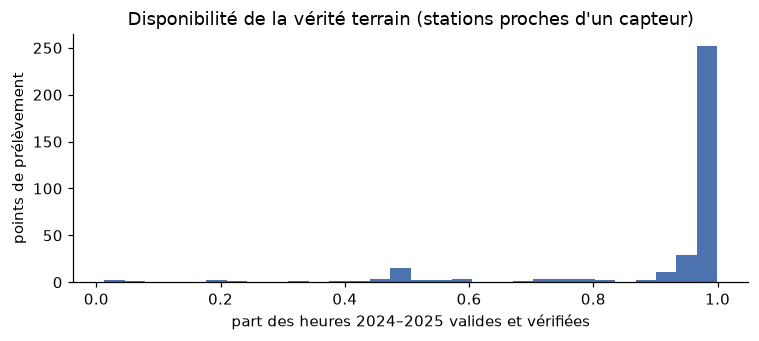

In [11]:
availability = pl.read_parquet(settings.paths.meta / "eea_pm25_monthly_valid_hours.parquet")
per_point = availability.group_by("sampling_point").agg(heures_valides=pl.col("valid_hours").sum())
hours_in_period = (settings.period.end - settings.period.start).days * 24 + 24
fig, ax = plt.subplots(figsize=(7, 3.2))
ax.hist(per_point["heures_valides"] / hours_in_period, bins=30, color="#4C72B0")
ax.set_xlabel("part des heures 2024–2025 valides et vérifiées")
ax.set_ylabel("points de prélèvement")
ax.set_title("Disponibilité de la vérité terrain (stations proches d'un capteur)")
fig.tight_layout()
fig.savefig(FIG_DIR / "01_disponibilite_eea.png")
median_share = (per_point["heures_valides"] / hours_in_period).median()
print(f"{per_point.height} points ; médiane = {median_share:.1%} des heures")

**Ce que nous observons.** Sur les 381 stations PM2.5 situées à moins de 3 km d'un capteur, 340 ont des données valides
et vérifiées en 2024–2025 (les 41 autres ont fermé ou changé d'instrument avant 2024). Pour ces 340 points, la médiane
est de **99 % d'heures utilisables**.

**Ce que ça veut dire.** La référence n'est pas le facteur limitant : ce sont les capteurs citoyens.

## 6. Sur quelle horloge sont les stations ?

**Question.** Les horodatages EEA n'ont pas de fuseau explicite. Les métadonnées annoncent `UTC+01` pour l'Allemagne et
`UTC` pour la France. Nous voulons le **vérifier** plutôt que le croire : un décalage d'une heure suffirait à dégrader
artificiellement tous les modèles.

**Ce que nous regardons.** Pour 7 capteurs SDS011 à moins de 260 m d'une station (4 en Allemagne, 3 en France), nous
calculons la moyenne horaire du capteur (en UTC, heure étiquetée par son début), puis sa corrélation avec la station
décalée de $k$ heures :

$$
r(k) = \operatorname{corr}\big(\,x_{\text{capteur}}(h),\; y_{\text{station}}(h + k)\,\big), \qquad k \in \{-3, \dots, +3\}
$$

où $x_{\text{capteur}}(h)$ est la moyenne du capteur pendant l'heure $h$, $y_{\text{station}}(h+k)$ la valeur de la
station étiquetée $h+k$, et $\operatorname{corr}$ la **corrélation de Pearson** (1 = les deux séries montent et
descendent ensemble, 0 = aucun lien). Le bon alignement est le $k$ qui maximise $r(k)$.

shape: (7, 7)
┌─────────┬───────────┬───────────────────────────────┬─────────────┬───────┬───────────┬─────────┐
│ country ┆ sensor_id ┆ sampling_point                ┆ distance_km ┆ lag_h ┆ pearson_r ┆ n_hours │
│ ---     ┆ ---       ┆ ---                           ┆ ---         ┆ ---   ┆ ---       ┆ ---     │
│ str     ┆ i32       ┆ str                           ┆ f64         ┆ i64   ┆ f64       ┆ i64     │
╞═════════╪═══════════╪═══════════════════════════════╪═════════════╪═══════╪═══════════╪═════════╡
│ FR      ┆ 65706     ┆ SPO-FR02020_6001              ┆ 0.133495    ┆ 1     ┆ 0.975464  ┆ 331     │
│ FR      ┆ 90258     ┆ SPO-FR12042_6001              ┆ 0.253462    ┆ 1     ┆ 0.954563  ┆ 335     │
│ DE      ┆ 515       ┆ SPO.DE_DEBW107_PM2_dataGroup1 ┆ 0.069007    ┆ 1     ┆ 0.937027  ┆ 324     │
│ DE      ┆ 81044     ┆ SPO.DE_DEBB044_PM2_dataGroup1 ┆ 0.0333      ┆ 1     ┆ 0.935762  ┆ 334     │
│ FR      ┆ 82196     ┆ SPO-FR12021_6001              ┆ 0.054572    ┆ 1     ┆ 0.909766

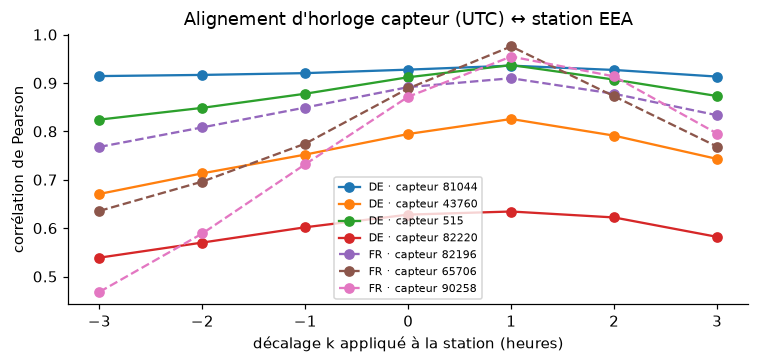

In [12]:
lags = pl.read_parquet(settings.paths.meta / "eea_clock_lag_check.parquet")
best = (
    lags.sort("pearson_r", descending=True)
    .group_by("country", "sensor_id", "sampling_point", maintain_order=True)
    .first()
)
print(best.select("country", "sensor_id", "sampling_point", "distance_km", "lag_h", "pearson_r", "n_hours"))
fig, ax = plt.subplots(figsize=(7, 3.4))
for (country, sensor_id), part in lags.group_by("country", "sensor_id", maintain_order=True):
    ax.plot(
        part["lag_h"],
        part["pearson_r"],
        marker="o",
        ls="-" if country == "DE" else "--",
        label=f"{country} · capteur {sensor_id}",
    )
ax.set_xlabel("décalage k appliqué à la station (heures)")
ax.set_ylabel("corrélation de Pearson")
ax.set_title("Alignement d'horloge capteur (UTC) ↔ station EEA")
ax.legend(fontsize=7)
fig.tight_layout()
fig.savefig(FIG_DIR / "01_controle_horloge.png")

**Ce que nous observons.** Pour les **7 paires**, la corrélation est maximale pour **$k = +1$ h, sans exception**
(r jusqu'à 0,98, avec un pic net). La valeur que l'EEA étiquette `Start = 14:00` correspond donc à l'heure 13:00–14:00
UTC, en Allemagne comme en France, alors que les métadonnées françaises annoncent UTC.

**Ce que ça veut dire.** En Allemagne, c'est conforme aux métadonnées (UTC+1, heure étiquetée par son début). En
France, soit l'heure est étiquetée par sa **fin**, soit l'horloge est UTC+1 : les deux hypothèses donnent la même
correction. Indice concordant : chaque fichier français commence à `01:00` le 1ᵉʳ janvier 2013.

**Décision.** Une règle unique pour les deux pays :

$$
\text{heure}_{\text{UTC}} = \texttt{Start} - 1\ \text{h}
$$

où $\texttt{Start}$ est l'horodatage du fichier EEA et $\text{heure}_{\text{UTC}}$ le début de l'heure en temps
universel.

> **🔎 Contrôle.** Ce test sur 7 paires sera refait automatiquement sur **chaque** paire et chaque station à
> l'étape 3 (notebook 03), avec une contre-épreuve. Sans lui, toutes les paires françaises auraient été décalées
> d'une heure.

## 7. Combien de paires capteur ↔ station pouvons-nous former ?

**Question.** C'est le cœur du GO / NO-GO : il faut assez de paires, sur assez de stations différentes (le modèle sera
évalué par station), avec assez d'heures communes et une sonde d'humidité.

**Ce que nous regardons.** Pour chaque capteur de particules extérieur, la distance à chaque station, sur la sphère
terrestre (formule de **haversine**) :

$$
d = 2R \arcsin\!\sqrt{\sin^2\!\frac{\varphi_2-\varphi_1}{2} + \cos\varphi_1 \cos\varphi_2 \sin^2\!\frac{\lambda_2-\lambda_1}{2}}
$$

où $\varphi_1, \varphi_2$ sont les latitudes et $\lambda_1, \lambda_2$ les longitudes des deux points (en radians), et
$R = 6\,371$ km le rayon de la Terre.

**Règle d'appariement : 1 capteur = 1 station.** Un capteur peut avoir jusqu'à 6 stations à moins de 3 km ; nous
gardons **la plus proche ayant des heures vérifiées pendant que le capteur est actif**, et sa distance. Plusieurs
capteurs peuvent partager une station. Pour chaque rayon, le tableau compte les paires (`n_pairs`, une par capteur),
les stations distinctes (`n_stations`), le recouvrement temporel médian en heures (`median_overlap_h`), la part des
capteurs ayant une sonde d'humidité sur le même site (`humidity_share`) et la part des paires dont la station est une
station trafic (`traffic_share`).

> **Correction du 14/10/2026.** La première version de ce tableau comptait tous les *couples* capteur ↔ station à moins
> du rayon (en Allemagne à 3 km : 1 876 couples pour 1 269 capteurs). Le nombre de capteurs était juste, mais le nombre
> de paires et de stations était gonflé. Le code applique désormais la règle ci-dessus (voir le journal).

In [13]:
pairs = pl.read_parquet(settings.paths.meta / "candidate_pairs.parquet")
assert pairs["sensor_id"].is_unique().all(), "one station per sensor"
print(
    "stations à portée par capteur (≤ 3 km) :",
    dict(pairs["n_stations_within"].value_counts().sort("n_stations_within").iter_rows()),
)
summary = discovery.feasibility_summary(pairs, settings.discovery.radii_km)
summary.with_columns(
    pl.col("humidity_share", "traffic_share").round(2), pl.col("total_overlap_h") / 1000
).rename({"total_overlap_h": "total_overlap_kh"})

stations à portée par capteur (≤ 3 km) : {1: 932, 2: 392, 3: 92, 4: 26, 5: 3, 6: 4}


country,radius_km,n_pairs,n_sensors,n_stations,median_overlap_h,total_overlap_kh,humidity_share,traffic_share
str,f64,u32,u32,u32,f64,f64,f64,f64
"""DE""",0.5,127,127,74,13055.0,1418.901,0.85,0.64
"""DE""",1.0,337,337,147,12287.0,3683.914,0.84,0.61
"""DE""",1.5,568,568,179,12473.5,6224.304,0.84,0.57
"""DE""",2.0,808,808,199,13008.5,9002.469,0.81,0.57
"""DE""",3.0,1268,1268,241,13094.5,14287.052,0.81,0.54
"""FR""",0.5,11,11,11,13719.0,125.171,0.73,0.18
"""FR""",1.0,30,30,26,12156.5,345.555,0.77,0.3
"""FR""",1.5,62,62,43,11010.5,647.884,0.76,0.34
"""FR""",2.0,97,97,53,10164.0,945.978,0.75,0.31


**Ce que nous observons.**

- **Une station par capteur** : 932 capteurs n'ont qu'une station utilisable à moins de 3 km, 392 en ont deux, 125 en
  ont trois ou plus.
- **Allemagne** : 127 capteurs appariables à 0,5 km, 337 à 1 km, **568 à 1,5 km (179 stations)**, 808 à 2 km, 1 268 à
  3 km (241 stations).
- **Recouvrement temporel** médian : environ 12 500 heures (70 % des 17 544 heures de la période), quel que soit le
  rayon.
- **Humidité** : environ 84 % des capteurs allemands ont une sonde d'humidité active sur le même site.
- **France** : neuf fois moins dense, 62 capteurs à 1,5 km (43 stations), 181 à 3 km (67 stations).
- À 1,5 km, **559 des 568** capteurs allemands sont des SDS011.

**Ce que ça veut dire.** L'Allemagne a assez de paires et de stations pour une validation croisée par station ; la
France suffit pour un test, pas pour apprendre.

Nous visualisons ces comptes selon le rayon, et la distribution des distances.

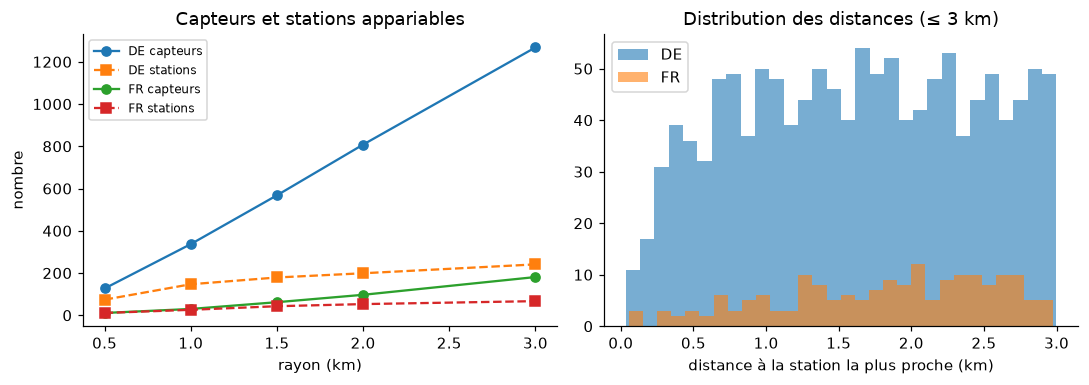

In [14]:
fig, axes = plt.subplots(1, 2, figsize=(10, 3.6))
for country, part in summary.group_by("country", maintain_order=True):
    axes[0].plot(part["radius_km"], part["n_sensors"], marker="o", label=f"{country[0]} capteurs")
    axes[0].plot(part["radius_km"], part["n_stations"], marker="s", ls="--", label=f"{country[0]} stations")
axes[0].set_xlabel("rayon (km)")
axes[0].set_ylabel("nombre")
axes[0].set_title("Capteurs et stations appariables")
axes[0].legend(fontsize=8)
nearest = pairs.sort("distance_km").unique("sensor_id", keep="first")
for country, part in nearest.group_by("country", maintain_order=True):
    axes[1].hist(part["distance_km"], bins=30, alpha=0.6, label=country[0])
axes[1].set_xlabel("distance à la station la plus proche (km)")
axes[1].set_title("Distribution des distances (≤ 3 km)")
axes[1].legend()
fig.tight_layout()
fig.savefig(FIG_DIR / "01_paires_par_rayon.png")

**Question.** Quel type de station est le plus proche des capteurs ?

**Ce que nous regardons.** À 1,5 km, la répartition des capteurs par pays et par type de station.

In [15]:
radius = 1.5
chosen = (
    pairs.filter(pl.col("distance_km") <= radius, pl.col("overlap_hours") > 0)
    .sort("distance_km")
    .unique("sensor_id", keep="first")
)
chosen.group_by("country", "station_type").agg(
    capteurs=pl.len(),
    stations=pl.col("station_code").n_unique(),
    heures_kh=(pl.col("overlap_hours").sum() / 1000).round(1),
).sort("country", "station_type")

country,station_type,capteurs,stations,heures_kh
str,str,u32,u32,f64
"""DE""","""background""",231,88,2556.0
"""DE""","""industrial""",12,7,107.1
"""DE""","""traffic""",325,84,3561.2
"""FR""","""background""",39,27,399.9
"""FR""","""industrial""",2,2,28.0
"""FR""","""traffic""",21,14,219.9


**Ce que nous observons.** À 1,5 km en Allemagne, **325 capteurs sur 568** (57 %) ont pour station la plus proche une
station **trafic**.

**Ce que ça veut dire.** La référence y est mesurée en bord de route, alors que le capteur citoyen est souvent sur un
balcon d'une rue voisine. Une partie de l'écart capteur ↔ station ne vient donc pas du capteur mais de la différence de
lieu : c'est l'**erreur de représentativité**, qu'aucune correction ne peut supprimer.

**Décision.** Le type de station sera une variable du modèle et un axe d'analyse de tous les résultats.

Pour situer les paires, la carte des capteurs extérieurs, des stations et des capteurs appariés à 1,5 km.

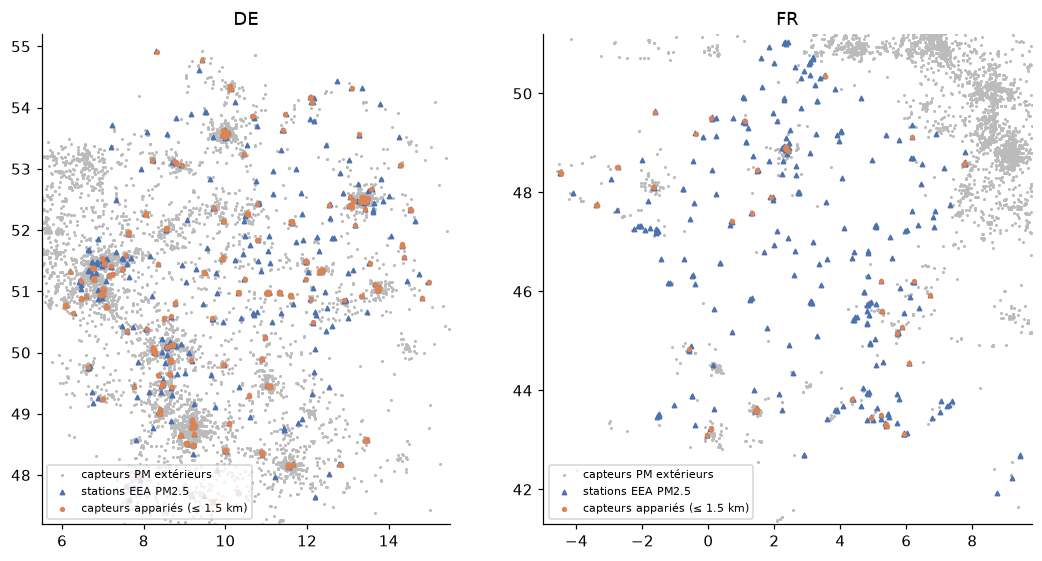

In [16]:
inv = pl.read_parquet(settings.paths.meta / "sc_inventory.parquet")
fig, axes = plt.subplots(1, 2, figsize=(10, 5.2))
boxes = {"DE": (5.5, 15.5, 47.2, 55.2), "FR": (-5.0, 9.8, 41.3, 51.2)}
for ax, (country, (x0, x1, y0, y1)) in zip(axes, boxes.items(), strict=True):
    pm = inv.filter(
        pl.col("kind") == "pm",
        ~pl.col("indoor"),
        pl.col("lon").is_between(x0, x1),
        pl.col("lat").is_between(y0, y1),
    )
    st = stations.filter(
        pl.col("country") == country, pl.col("lon").is_between(x0, x1), pl.col("lat").is_between(y0, y1)
    )
    pr = chosen.filter(pl.col("country") == country)
    ax.scatter(pm["lon"], pm["lat"], s=1, c="#BBBBBB", label="capteurs PM extérieurs")
    ax.scatter(st["lon"], st["lat"], s=8, c="#4C72B0", marker="^", label="stations EEA PM2.5")
    ax.scatter(
        pr["sensor_lon"], pr["sensor_lat"], s=6, c="#DD8452", label=f"capteurs appariés (≤ {radius} km)"
    )
    ax.set_title(country)
    ax.set_xlim(x0, x1)
    ax.set_ylim(y0, y1)
    ax.set_aspect(1.5)
    ax.legend(fontsize=7, loc="lower left")
fig.tight_layout()
fig.savefig(FIG_DIR / "01_carte_paires.png")

## 8. Quel volume disque attendre ?

**Question.** Notre budget est de 5–10 Go au final et 20 Go au plus fort du traitement. Nous voulons un ordre de
grandeur **mesuré**, pas supposé.

**Ce que nous regardons.** Une semaine réelle pour quelques capteurs appariés de chaque type : taille du fichier
compressé (gzip) et du même contenu converti en **Parquet** (un format de fichier en colonnes, compressé, rapide à
lire), puis une extrapolation aux capteurs retenus sur 731 jours.

In [17]:
humidity_sites = inv.filter(pl.col("kind") == "humidity", ~pl.col("indoor")).select(
    "sensor_id", "sensor_type", "location_id"
)
chosen_humidity = humidity_sites.join(chosen.select("location_id").unique(), on="location_id")
probe_set = pl.concat(
    [
        chosen.filter(pl.col("sensor_type") == "sds011").head(4).select("sensor_type", "sensor_id"),
        chosen_humidity.filter(pl.col("sensor_type") == "bme280").head(3).select("sensor_type", "sensor_id"),
        chosen_humidity.filter(pl.col("sensor_type") == "dht22").head(3).select("sensor_type", "sensor_id"),
    ]
)
probe = await discovery.size_probe(settings, probe_set, date(2025, 3, 3), 7, TODAY)
probe.group_by("sensor_type").agg(
    capteurs=pl.len(),
    lignes_par_jour=(pl.col("rows").sum() / pl.col("days").sum()).round(0),
    ko_gz_par_jour=(pl.col("gz_bytes").sum() / pl.col("days").sum() / 1e3).round(1),
    ko_parquet_1_fichier_par_jour=(pl.col("parquet_daily_bytes").sum() / pl.col("days").sum() / 1e3).round(1),
    ko_parquet_regroupé=(pl.col("parquet_batched_bytes").sum() / pl.col("days").sum() / 1e3).round(1),
).sort("sensor_type")

sensor_type,capteurs,lignes_par_jour,ko_gz_par_jour,ko_parquet_1_fichier_par_jour,ko_parquet_regroupé
str,u32,f64,f64,f64,f64
"""bme280""",1,563.0,7.8,10.4,7.6
"""dht22""",1,558.0,3.9,6.4,3.4
"""sds011""",1,574.0,6.2,9.1,5.8


Nous extrapolons maintenant à chaque rayon d'appariement.

In [18]:
per_day = probe.select(
    gz=pl.col("gz_bytes").sum() / pl.col("days").sum(),
    bronze=pl.col("parquet_batched_bytes").sum() / pl.col("days").sum(),
).row(0, named=True)
# Measured at step 1 on the raw files (since deleted once in bronze, see the journal); 0 if absent.
eea_pm25 = sum(p.stat().st_size for p in (settings.paths.raw / "eea" / "pm25").rglob("*.parquet"))
rows = []
for r in (1.0, 1.5, 3.0):
    sel = (
        pairs.filter(pl.col("distance_km") <= r, pl.col("overlap_hours") > 0)
        .sort("distance_km")
        .unique("sensor_id", keep="first")
    )
    hum = humidity_sites.join(sel.select("location_id").unique(), on="location_id")
    active = sel["overlap_hours"].sum() / (sel.height * hours_in_period)
    days = (sel.height + hum.height) * 731 * active
    rows.append(
        {
            "rayon_km": r,
            "capteurs_PM": sel.height,
            "sondes_humidité": hum.height,
            "part_jours_actifs": round(active, 2),
            "fichiers_capteur_jour": int(days),
            "téléchargement_gz_Go": round(days * per_day["gz"] / 1e9, 2),
            "bronze_parquet_Go": round(days * per_day["bronze"] / 1e9, 2),
        }
    )
print(f"EEA PM2.5 (stations à ≤ 3 km, historique complet 2013–2025) : {eea_pm25 / 1e9:.2f} Go")
pl.DataFrame(rows)

EEA PM2.5 (stations à ≤ 3 km, historique complet 2013–2025) : 0.00 Go


rayon_km,capteurs_PM,sondes_humidité,part_jours_actifs,fichiers_capteur_jour,téléchargement_gz_Go,bronze_parquet_Go
f64,i64,i64,f64,i64,f64,f64
1.0,367,314,0.63,311542,1.86,1.75
1.5,630,532,0.62,528140,3.15,2.96
3.0,1449,1170,0.63,1202454,7.17,6.74


**Ce que nous observons.**

- Sur une semaine réelle (6 capteurs × 7 jours) : 4 à 6 Ko par jour en gzip, 3 à 6 Ko en Parquet si les jours sont
  **regroupés** dans un même fichier ; écrit « un fichier par jour », le Parquet est plus gros que le gzip (l'en-tête de
  chaque fichier pèse).
- **À 1,5 km** : environ 0,53 million de fichiers capteur-jour, 2,8 Go transférés puis supprimés, **2,5 Go en
  bronze**. À 3 km : environ 5,6 Go. Il faut ajouter environ 0,8 Go pour l'EEA.
- Au débit mesuré (65 requêtes/s), 1,5 km représente environ 3 h de téléchargement, 3 km environ 6 h.

**Ce que ça veut dire.** Le volume tient dans le budget ; le facteur limitant est le temps, une seule fois et
reprenable. **Décision** : la couche bronze regroupera les jours par capteur et par mois.

## 9. Conclusion : GO

| Critère | Valeur mesurée | Verdict |
|---|---|---|
| Rayon d'apprentissage | **1,5 km** (station la plus proche) | compromis taille / représentativité |
| Période | 2024-01-01 → 2025-12-31, vérité terrain E1a vérifiée à 100 % | ✅ |
| Paires Allemagne (apprentissage) | **568 capteurs**, 179 stations, environ 6,2 millions d'heures communes estimées | ✅ |
| Paires France (transfert) | 62 capteurs, 43 stations, environ 0,65 million d'heures | ✅ pour un test |
| Sonde d'humidité sur le même site | 84 % (DE), 76 % (FR) | ✅ |
| Alignement horaire | vérifié : `heure_UTC = Start − 1 h` (DE et FR) | ✅ |
| Disque estimé | environ 2,5 Go de bronze capteurs + 0,8 Go EEA | ✅ (budget 5–10 Go) |
| Téléchargement | environ 3 h, une fois, reprenable | acceptable |

**Décision : le rayon.** Trois options : 0,5 km (127 capteurs, 75 stations : trop peu pour une validation par station
robuste), 3 km (1 268 capteurs, mais un écart de lieu capteur ↔ station plus grand, qui brouille la cible) et 1,5 km
(568 capteurs, avec une distance qui varie assez pour étudier l'erreur selon la distance). Nous retenons 1,5 km pour
apprendre.

**Décision du feu vert (14/10/2026).** Nous **téléchargeons toutes les paires jusqu'à 3 km** mais nous **n'apprenons
que sur les paires à 1,5 km ou moins** ; les paires entre 1,5 et 3 km forment un test « distance » qui répond
directement à la seconde moitié de la question business. Seul le **SDS011** est conservé (98 % des paires
allemandes). Ce que nous perdons : les capteurs PMS et SPS, trop rares pour apprendre.

**Risques identifiés, et leur parade.**

1. Humidité saturée chez environ la moitié des mesures d'un échantillon de mars → règle de qualité dédiée (notebook 02).
2. 57 % des capteurs allemands appariés sont près d'une station trafic → type de station en variable et en axe
   d'analyse.
3. Activité connue au mois près → recalculée exactement au téléchargement.
4. Instruments de référence différents entre pays → limite explicite du test de transfert.

## Ce qu'il faut retenir

- **GO** : 568 capteurs allemands à 1,5 km ou moins de 179 stations, soit environ 6,2 millions d'heures communes ; la
  France (62 capteurs) sert de test.
- La vérité terrain EEA de 2024–2025 est **vérifiée à 100 %** ; la médiane des stations a 99 % d'heures utilisables.
- 🔎 L'horloge des stations est décalée d'une heure par rapport à l'UTC, **France comprise** malgré ses métadonnées :
  règle `heure_UTC = Start − 1 h`.
- L'humidité des sondes est saturée la moitié du temps en mars : c'est le premier risque du projet.
- 57 % des capteurs allemands sont près d'une station trafic : l'erreur de représentativité sera suivie partout.